In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import StrMethodFormatter

In [3]:
# Locate the project directory.
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

# Locate the ABS property price dataset.
file = root / "data/raw/ABS property-price.xlsx"

# Inspect the available Excel worksheets.
excel = pd.ExcelFile(file)
print("Worksheets:", excel.sheet_names)

Worksheets: ['Index', 'Data1', 'Enquiries']


We begin by examining the structure of the ABS property-price dataset, including its worksheets, dimensions, and initial rows.

**Purpose:** Identify the relevant housing-price variables, observation periods, and header structure before performing data cleaning and exploratory analysis.

In [6]:
# Load the first worksheet without assuming where the headers are.
df = pd.read_excel(file, sheet_name=0, header=None)
print(excel.sheet_names)

['Index', 'Data1', 'Enquiries']


The initial worksheet contains metadata describing the ABS housing-price series, including their identifiers, units, and observation periods.

We inspect the remaining worksheets to locate the actual quarterly observations before selecting and cleaning the relevant property-price data.

In [7]:
# Load the worksheet containing historical observations.
data = pd.read_excel(file, sheet_name="Data1", header=None)

# Inspect its structure before cleaning.
print("Shape:", data.shape)
display(data.iloc[:15, :8])

Shape: (108, 61)


,0,1,2,3,4,5,6,7
0,NaN,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...,Median Price of Established House Transfers (U...
1,Unit,$'000,$'000,$'000,$'000,$'000,$'000,$'000
2,Series Type,Original,Original,Original,Original,Original,Original,Original
3,Data Type,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3
6,Series Start,2002-03-01 00:00:00,2003-09-01 00:00:00,2002-03-01 00:00:00,2003-09-01 00:00:00,2002-03-01 00:00:00,2003-09-01 00:00:00,2002-03-01 00:00:00
7,Series End,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00
8,No. Obs,98,92,98,92,98,92,98
9,Series ID,A83728545T,A83728577K,A83728549A,A83728581A,A83728553T,A83728585K,A83728557A


The Data1 worksheet contains quarterly observations, with the first 10 rows providing series descriptions and metadata.

We identify the median established-house price series for Australian capital cities to ensure consistent comparisons across locations.

**Purpose:** Select the appropriate housing-price variables before cleaning and conducting exploratory analysis.

In [8]:
# Identify columns containing established house prices.
for col, name in data.iloc[0].items():
    if "Median Price of Established House Transfers" in str(name):
        print(col, name)

1 Median Price of Established House Transfers (Unstratified) ;  Sydney ;
2 Median Price of Established House Transfers (Unstratified) ;  Rest of NSW ;
3 Median Price of Established House Transfers (Unstratified) ;  Melbourne ;
4 Median Price of Established House Transfers (Unstratified) ;  Rest of Vic. ;
5 Median Price of Established House Transfers (Unstratified) ;  Brisbane ;
6 Median Price of Established House Transfers (Unstratified) ;  Rest of Qld. ;
7 Median Price of Established House Transfers (Unstratified) ;  Adelaide ;
8 Median Price of Established House Transfers (Unstratified) ;  Rest of SA ;
9 Median Price of Established House Transfers (Unstratified) ;  Perth ;
10 Median Price of Established House Transfers (Unstratified) ;  Rest of WA ;
11 Median Price of Established House Transfers (Unstratified) ;  Hobart ;
12 Median Price of Established House Transfers (Unstratified) ;  Rest of Tas. ;
13 Median Price of Established House Transfers (Unstratified) ;  Darwin ;
14 Median 

In [13]:
# Identify capital-city series, excluding "Rest of State" regions.
cities = {
    col: str(name).split(";")[1].strip()
    for col, name in data.iloc[0].items()
    if "Median Price of Established House Transfers (Unstratified)" in str(name)
    and "Rest of" not in str(name)
}

# Verify the number of capital cities and their column positions.
print("Number of capital cities:", len(cities))

for i, city in cities.items():
    print(i, ": ", city)

Number of capital cities: 8
1 :  Sydney
3 :  Melbourne
5 :  Brisbane
7 :  Adelaide
9 :  Perth
11 :  Hobart
13 :  Darwin
15 :  Canberra


We select the median established-house transfer price series for Australia's eight capital cities.

The dataset is cleaned by converting dates and prices into appropriate data types, removing missing observations, and converting prices from thousands of dollars into AUD.

We focus on 2015–2026 and restructure the data into a long format to simplify comparisons, visualisation, and subsequent machine learning.

In [14]:
# Extract quarterly observations for the eight capital cities.
prices = data.iloc[10:, [0] + list(cities)].copy()
prices.columns = ["date"] + list(cities.values())

# Convert dates and prices to the appropriate data types.
prices["date"] = pd.to_datetime(prices["date"], errors="coerce")

for city in cities.values():
    prices[city] = pd.to_numeric(prices[city], errors="coerce") * 1000

# Keep observations from 2015 onwards.
prices = prices[prices["date"] >= "2015-01-01"]

# Convert to long format for easier analysis.
prices = prices.melt(
    id_vars="date",
    var_name="city",
    value_name="median_price_aud"
).dropna().sort_values(["city", "date"]).reset_index(drop=True)

display(prices.head())

,date,city,median_price_aud
0,2015-03-01,Adelaide,415500.0
1,2015-06-01,Adelaide,420000.0
2,2015-09-01,Adelaide,427500.0
3,2015-12-01,Adelaide,436000.0
4,2016-03-01,Adelaide,436000.0


In [15]:
print("Dataset shape:", prices.shape)
print("Missing values:\n", prices.isnull().sum())
print("Duplicate records:", prices.duplicated(["date", "city"]).sum())

display(prices.groupby("city")["median_price_aud"].agg(["count", "min", "max"]))

Dataset shape: (368, 3)
Missing values:
 date                0
city                0
median_price_aud    0
dtype: int64
Duplicate records: 0


,count,min,max
city,,,
Adelaide,46,415500.0,985000.0
Brisbane,46,462800.0,1160000.0
Canberra,46,580000.0,1080000.0
Darwin,46,465000.0,752500.0
Hobart,46,340000.0,765000.0
Melbourne,46,525000.0,940000.0
Perth,46,475000.0,1010000.0
Sydney,46,792500.0,1570000.0


We visualise Perth's quarterly median established-house transfer prices from 2015 to 2026.

Purpose: Identify long-term trends, periods of price increases or declines, and potential changes in the housing market before investigating economic factors associated with price growth.

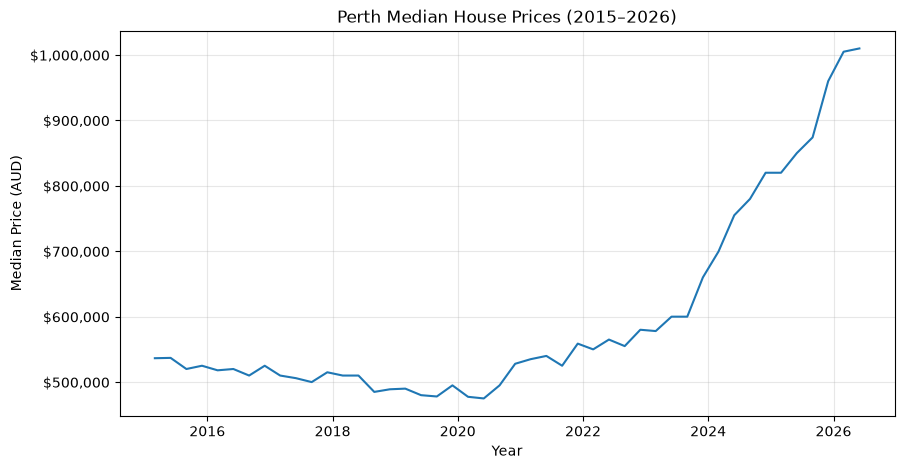

In [19]:
# Filter and sort Perth's historical property prices.
perth = prices[prices["city"] == "Perth"].sort_values("date")

# Visualise quarterly median house prices.
plt.figure(figsize=(10, 5))
plt.plot(perth["date"], perth["median_price_aud"])
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.title("Perth Median House Prices (2015–2026)")
plt.xlabel("Year")
plt.ylabel("Median Price (AUD)")
plt.grid(alpha=0.3)
plt.show()

## Perth Median House Prices (2015–2026)
- Perth's median house prices gradually declined from approximately $535,000 in 2015 to around $475,000 in 2020.
- Prices began recovering around 2021, with relatively moderate growth until 2023.
- A substantial acceleration occurred from 2023 onwards, with median prices exceeding $1 million by 2026.

Overall, Perth experienced a prolonged period of relatively stagnant or declining house prices, followed by rapid growth, particularly after 2023.

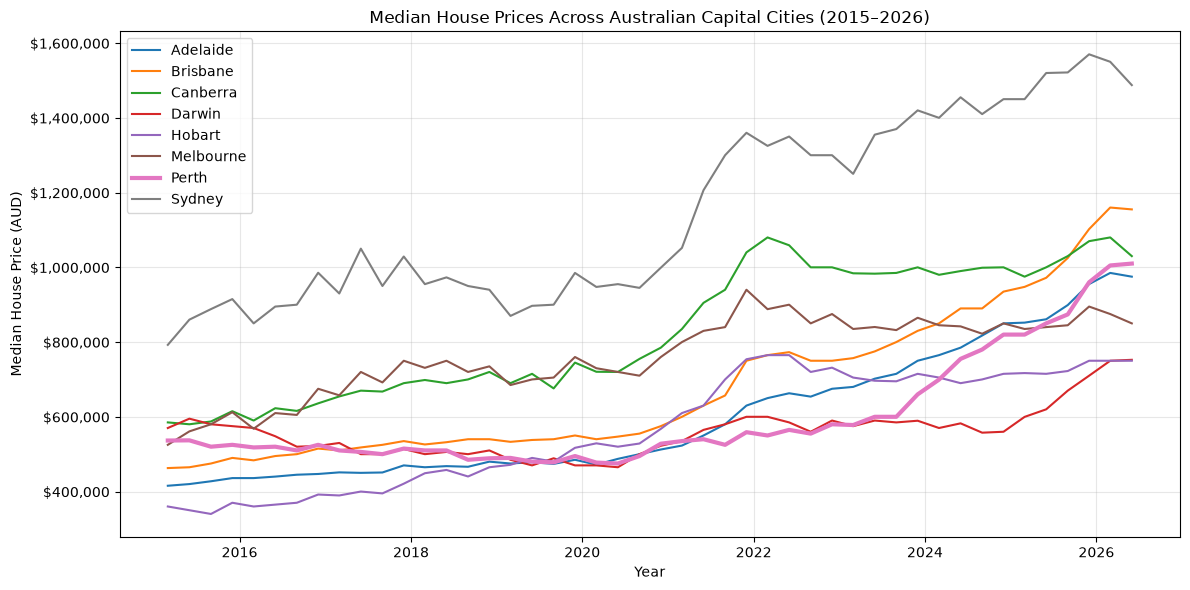

In [18]:
plt.figure(figsize=(12, 6))

# Compare median house prices across all capital cities.
for city, group in prices.groupby("city"):
    plt.plot(
        group["date"],
        group["median_price_aud"],
        label=city,
        linewidth=3 if city == "Perth" else 1.5
    )

# Format the Y-axis as actual AUD values.
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.title("Median House Prices Across Australian Capital Cities (2015–2026)")
plt.xlabel("Year")
plt.ylabel("Median House Price (AUD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Comparison Across Australian Capital Cities (2015–2026)

- Sydney consistently recorded the highest median house prices throughout the observed period.
- Brisbane, Adelaide, and Perth experienced substantial price increases, particularly after 2021.
- Melbourne experienced strong growth before 2022 but showed weaker performance in subsequent years.
- Perth's median house prices increased rapidly from 2023, overtaking several other capital cities by 2026.
- Housing-price growth varied considerably across cities, suggesting different regional market conditions.

Overall, Australia's housing markets did not experience uniform growth. Perth's recent price acceleration stands out, particularly compared with Melbourne's relatively weaker performance.

The visualisations suggest that Perth experienced a significant change in its housing-price trajectory around 2021–2023.

However, these trends alone cannot explain why prices increased. Further analysis of population growth, housing supply, interest rates, and other economic indicators is required.

Additionally, median transfer prices may be affected by changes in the mix of properties sold, so they should not be interpreted as pure changes in property values.

In [22]:
# Calculate year-on-year house price growth for each city.
prices["yoy_growth_pct"] = (
    prices.groupby("city")["median_price_aud"]
    .pct_change(periods=4) * 100
)

# Inspect Perth's recent growth.
display(
    prices[prices["city"] == "Perth"]
    [["date", "median_price_aud", "yoy_growth_pct"]]
    .tail(10)
)

,date,median_price_aud,yoy_growth_pct
312,2024-03-01,699500.0,21.020761
313,2024-06-01,755000.0,25.833333
314,2024-09-01,780000.0,30.000000
315,2024-12-01,820000.0,24.242424
316,2025-03-01,820000.0,17.226590
317,2025-06-01,850000.0,12.582781
318,2025-09-01,874000.0,12.051282
319,2025-12-01,960000.0,17.073171
320,2026-03-01,1005000.0,22.560976
321,2026-06-01,1010000.0,18.823529


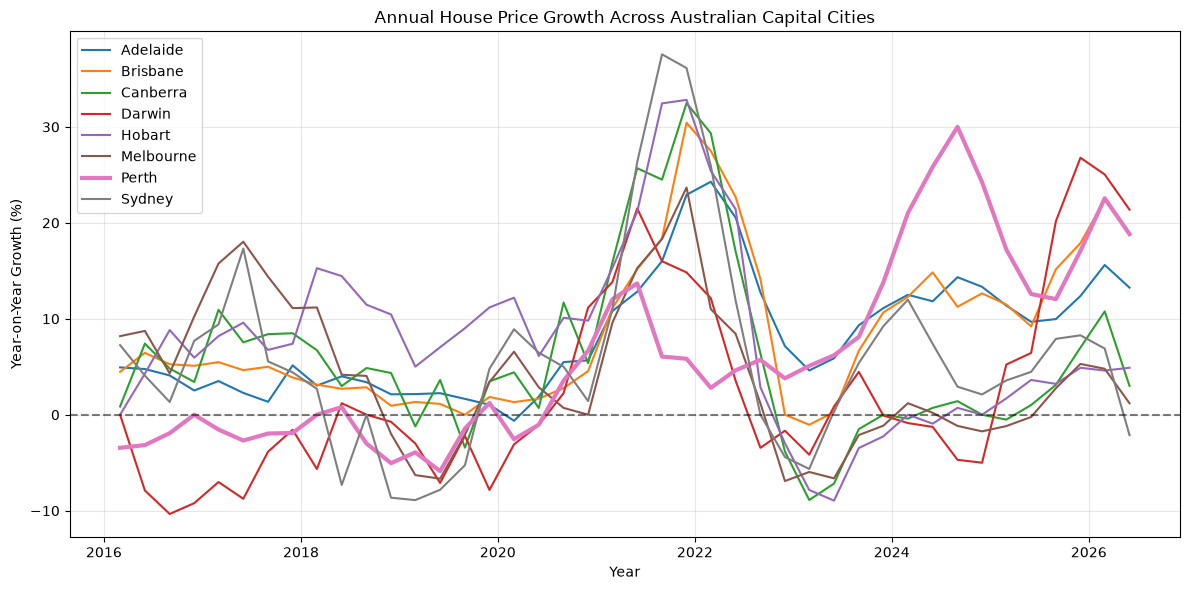

In [23]:
plt.figure(figsize=(12, 6))

# Plot annual growth for each capital city.
for city, group in prices.groupby("city"):
    plt.plot(
        group["date"],
        group["yoy_growth_pct"],
        label=city,
        linewidth=3 if city == "Perth" else 1.5
    )

plt.axhline(0, color="black", linestyle="--", alpha=0.5)

plt.title("Annual House Price Growth Across Australian Capital Cities")
plt.xlabel("Year")
plt.ylabel("Year-on-Year Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The EDA reveals two distinct periods of housing-price growth, suggesting that different economic conditions may have influenced the Australian property market.

**1. Post-COVID Housing Boom (2020–2022)**

During the initial COVID-19 lockdowns, reduced mobility and economic activity prompted expansionary monetary policy. The RBA lowered interest rates to historic lows, reducing borrowing costs and increasing mortgage affordability.

As restrictions eased, housing demand recovered, supported by cheaper financing and accumulated household savings. With housing supply relatively constrained, stronger demand contributed to upward pressure on property prices.

**2. Perth's Housing Boom (2023–2026)**

Despite higher interest rates, Perth experienced another substantial increase in median house prices.

This suggests that monetary policy alone cannot fully explain Perth's housing-market performance. Strong population growth, increased migration, and constraints on new housing supply may have contributed to continued price pressures.

**3. Business and Economic Implications**

These observations suggest that housing prices are influenced by interactions between demand, supply, financing conditions, and demographic changes.

Understanding these relationships is relevant to property investors, developers, financial institutions, and policymakers when evaluating market conditions and risks.

Implications for Machine Learning

The findings motivate incorporating interest rates, population growth, migration, and housing supply indicators as potential explanatory features.

The objective is to determine whether these variables improve predictions of house-price growth and identify meaningful statistical relationships, without assuming that predictive importance establishes causation.

We incorporate historical population estimates from the Australian Bureau of Statistics (ABS) to investigate whether population growth is associated with house-price growth across Australian capital cities.

**Purpose:** Identify the relevant capital-city population series and prepare the data for integration with our housing-price dataset.

In [24]:
# Locate the ABS population dataset.
population_file = root / "data/raw/ABS Regional Population 01–25.xlsx"

# Inspect the available worksheets.
population_excel = pd.ExcelFile(population_file)

print(population_excel.sheet_names)

['Contents', 'Table 1', 'Table 2', 'Table 3', 'Table 4', 'Table 5']


In [25]:
# Inspect the first worksheet before cleaning.
population_raw = pd.read_excel(
    population_file,
    sheet_name=0,
    header=None
)

display(population_raw.head(15))

,0,1
0,This tab outlines the contents of the datacube...,NaN
1,"Population estimates by SA2 and above, 2001 to...",NaN
2,"Regional population, 2024–25",NaN
3,Released at 11.30am (Canberra time) 31 March 2026,NaN
4,Contents,NaN
5,Tab,Description
6,Table 1,"Estimated resident population, Statistical Are..."
7,Table 2,"Estimated resident population, Statistical Are..."
8,Table 3,"Estimated resident population, Statistical Are..."
9,Table 4,"Estimated resident population, Greater Capital..."


We select Table 4, which contains historical population estimates for Australia's Greater Capital City Statistical Areas (GCCSAs).

In [26]:
# Load population estimates for Greater Capital City Statistical Areas.
population_raw = pd.read_excel(
    population_file,
    sheet_name="Table 4",
    header=None
)

# Inspect the structure before cleaning.
print("Dataset shape:", population_raw.shape)
display(population_raw.iloc[:15, :12])

Dataset shape: (26, 33)


,0,1,2,3,4,5,6,7,8,9,10,11
0,This tab has one table with the estimated resi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Table 4. Estimated resident population, Greate...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Regional population, 2024–25",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,ERP at 30 June (a),NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,2001,2002,2003,2004,2005,2006,2007,2008
5,S/T code,S/T name,GCCSA code,GCCSA name,no.,no.,no.,no.,no.,no.,no.,no.
6,1,New South Wales,1GSYD,Greater Sydney,4102580,4135637,4162593,4184763,4217563,4256161,4325525,4409562
7,1,New South Wales,1RNSW,Rest of NSW,2427769,2445170,2458122,2465972,2475643,2486529,2508631,2533899
8,2,Victoria,2GMEL,Greater Melbourne,3500249,3545579,3594031,3641951,3697372,3760760,3841760,3931438
9,2,Victoria,2RVIC,Rest of Vic.,1263366,1272195,1279778,1285198,1291874,1300506,1311762,1324937


In [27]:
# Inspect the geographic areas and their corresponding codes.
display(population_raw.iloc[6:30, [2, 3]])

,2,3
6,1GSYD,Greater Sydney
7,1RNSW,Rest of NSW
8,2GMEL,Greater Melbourne
9,2RVIC,Rest of Vic.
10,3GBRI,Greater Brisbane
11,3RQLD,Rest of Qld
12,4GADE,Greater Adelaide
13,4RSAU,Rest of SA
14,5GPER,Greater Perth
15,5RWAU,Rest of WA


In [31]:
# Inspect the years available in the population dataset.
for i in population_raw.iloc[4, 5:].dropna().tolist():
    print(i)

2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
2023
2024
2025


We extract annual population estimates for Australia's eight capital cities from 2015 to 2025.

The data is transformed into a long format containing city, year, and population. We then calculate annual population growth rates to measure changes in potential housing demand.

**Purpose:** Prepare population growth as an economic indicator for investigating its relationship with house-price growth.

**Note:** ACT population is used as an approximation for Canberra due to differences in geographic classifications.

In [32]:
# Map ABS geographic codes to capital-city names.
city_codes = {
    "1GSYD": "Sydney",
    "2GMEL": "Melbourne",
    "3GBRI": "Brisbane",
    "4GADE": "Adelaide",
    "5GPER": "Perth",
    "6GHOB": "Hobart",
    "7GDAR": "Darwin",
    "8ACTE": "Canberra"
}

# Identify the year columns from 2015 to 2025.
years = pd.to_numeric(population_raw.iloc[4], errors="coerce")
cols = years[years.between(2015, 2025)].index

# Extract the population estimates for the eight cities.
population = population_raw.loc[
    population_raw[2].isin(city_codes), [2, *cols]
].copy()

population.columns = ["city", *years[cols].astype(int)]
population["city"] = population["city"].map(city_codes)

# Convert to long format.
population = population.melt(
    id_vars="city",
    var_name="year",
    value_name="population"
)

population["population"] = pd.to_numeric(population["population"], errors="coerce")

population = population.sort_values(["city", "year"]).reset_index(drop=True)

display(population.head())

,city,year,population
0,Adelaide,2015,1313419
1,Adelaide,2016,1324057
2,Adelaide,2017,1338270
3,Adelaide,2018,1353662
4,Adelaide,2019,1372414


The housing-price dataset contains quarterly observations, while population estimates are recorded annually at 30 June.

To ensure temporal consistency, we select the June-quarter median house price for each capital city and calculate its year-on-year percentage change.

In [33]:
# Extract June-quarter housing prices.
annual_prices = prices[prices["date"].dt.month == 6].copy()

# Extract the year.
annual_prices["year"] = annual_prices["date"].dt.year

# Keep relevant columns.
annual_prices = annual_prices[
    ["year", "city", "median_price_aud"]
].sort_values(["city", "year"])

# Calculate annual house-price growth.
annual_prices["price_growth_pct"] = (
    annual_prices.groupby("city")["median_price_aud"]
    .pct_change() * 100
)

display(annual_prices.head())

,year,city,median_price_aud,price_growth_pct
1,2015,Adelaide,420000.0,NaN
5,2016,Adelaide,440000.0,4.761905
9,2017,Adelaide,450000.0,2.272727
13,2018,Adelaide,468000.0,4.000000
17,2019,Adelaide,478500.0,2.243590


In [34]:
print("Number of cities:", annual_prices["city"].nunique())
print("Years:", annual_prices["year"].min(), "-", annual_prices["year"].max())

display(annual_prices.groupby("city").size())

Number of cities: 8
Years: 2015 - 2026


city
Adelaide     12
Brisbane     12
Canberra     12
Darwin       12
Hobart       12
Melbourne    12
Perth        12
Sydney       12
dtype: int64

In [37]:
# Sort population data chronologically for each city.
population = population.sort_values(["city", "year"])

# Calculate annual population growth (%).
population["population_growth_pct"] = (
    population.groupby("city")["population"].pct_change() * 100
)

# Merge annual housing and population data.
combined = annual_prices.merge(
    population[["city", "year", "population_growth_pct"]],
    on=["city", "year"],
    how="inner"
)

display(combined.head())

,year,city,median_price_aud,price_growth_pct,population_growth_pct
0,2015,Adelaide,420000.0,NaN,NaN
1,2016,Adelaide,440000.0,4.761905,0.809947
2,2017,Adelaide,450000.0,2.272727,1.073443
3,2018,Adelaide,468000.0,4.000000,1.150142
4,2019,Adelaide,478500.0,2.243590,1.385279


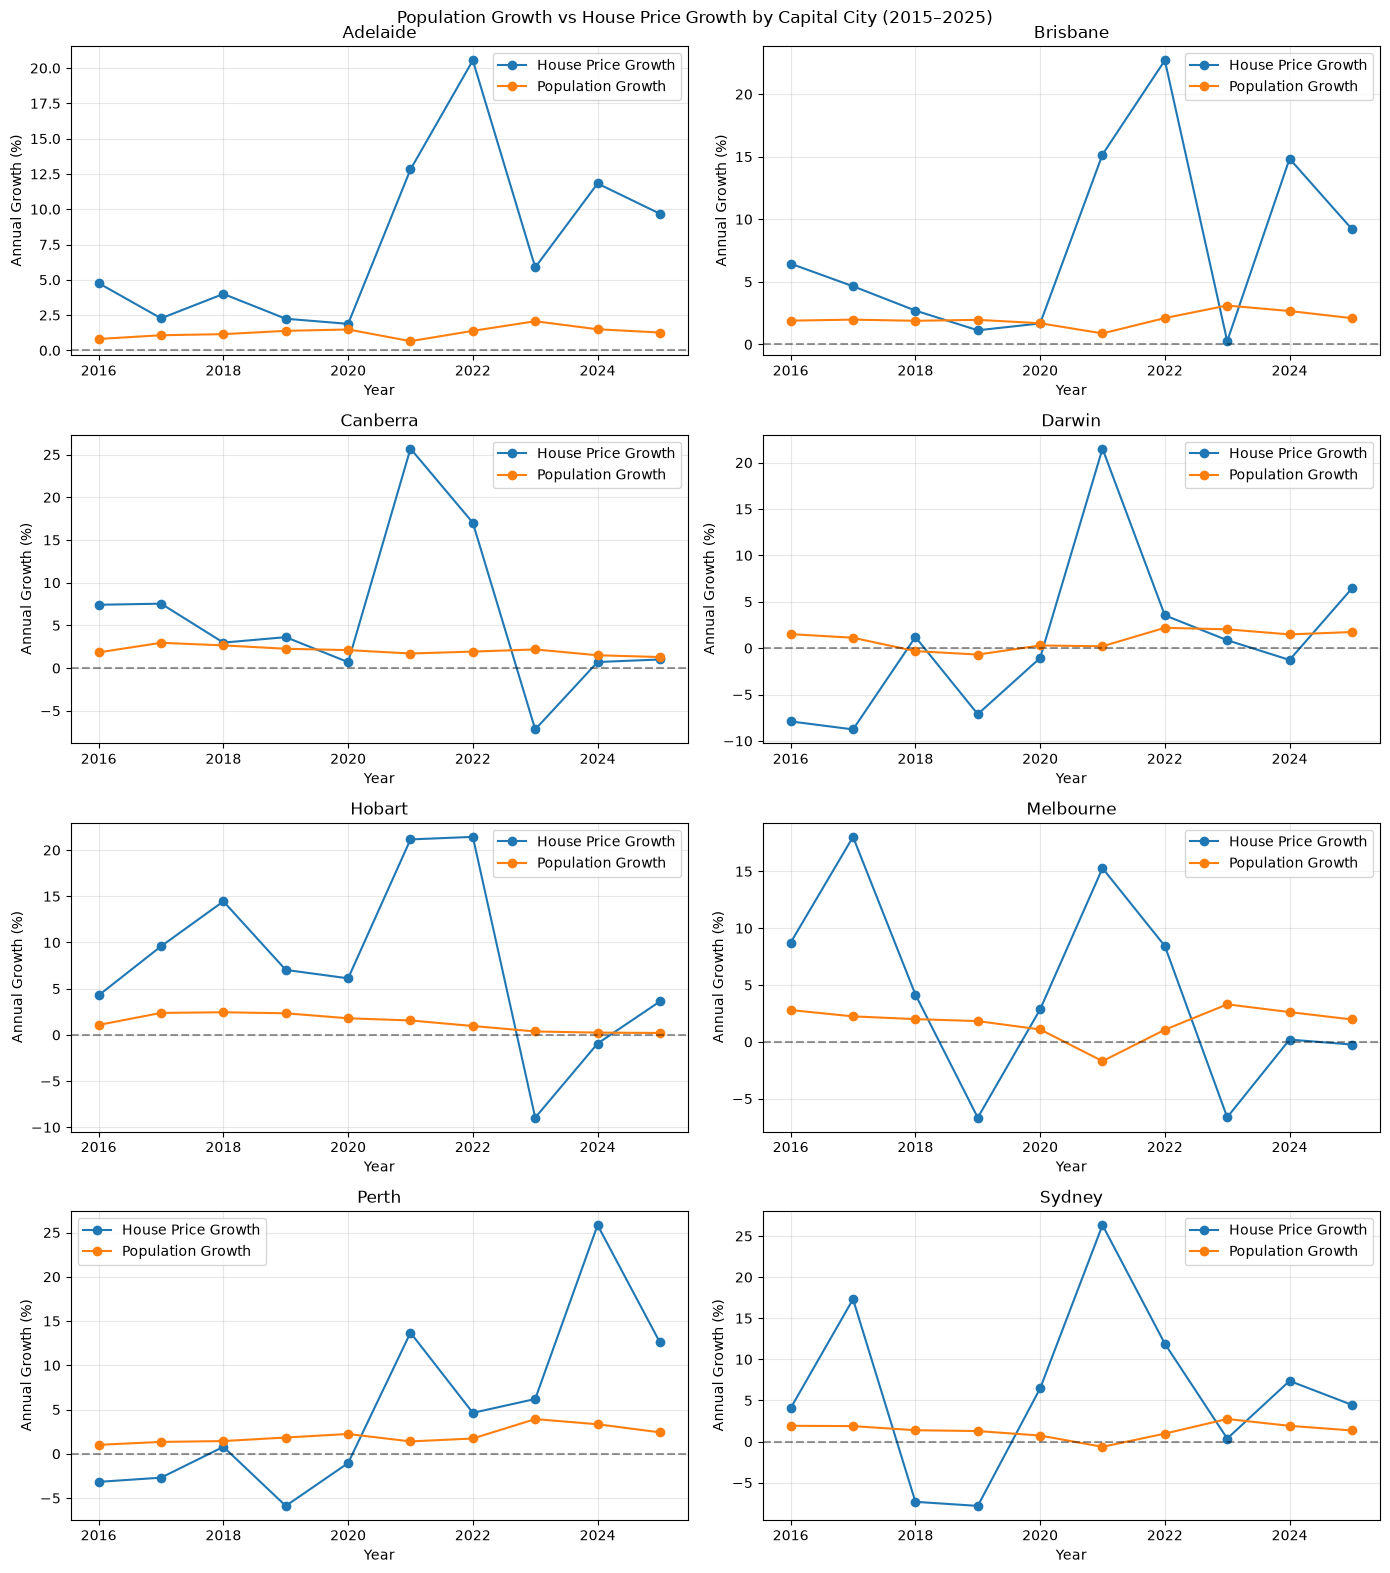

In [39]:
# Create a separate chart for each capital city.
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, (city, group) in zip(axes.flat, combined.groupby("city")):
    group = group.dropna(subset=["price_growth_pct", "population_growth_pct"])

    ax.plot(group["year"], group["price_growth_pct"],
            marker="o", label="House Price Growth")

    ax.plot(group["year"], group["population_growth_pct"],
            marker="o", label="Population Growth")

    ax.axhline(0, color="black", linestyle="--", alpha=0.4)
    ax.set_title(city)
    ax.set_ylabel("Annual Growth (%)")
    ax.set_xlabel("Year")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Population Growth vs House Price Growth by Capital City (2015–2025)")
plt.tight_layout()
plt.show()

The visual comparison does not reveal a consistent relationship between annual population growth and house-price growth across the eight capital cities.

House-price growth exhibits considerably greater volatility than population growth, suggesting that population changes alone are insufficient to explain housing-market movements.

However, population growth may influence prices with a time lag, and its effects may depend on housing supply and broader economic conditions.

In [40]:
# Calculate the correlation between population growth and house-price growth.
correlations = combined.groupby("city").apply(
    lambda x: x["population_growth_pct"].corr(x["price_growth_pct"]),
    include_groups=False
)

display(correlations.rename("Pearson Correlation").round(3))

city
Adelaide    -0.055
Brisbane    -0.186
Canberra    -0.109
Darwin      -0.019
Hobart       0.487
Melbourne   -0.486
Perth        0.533
Sydney      -0.524
Name: Pearson Correlation, dtype: float64

Pearson correlation was calculated to examine the relationship between annual population growth and house-price growth across eight Australian capital cities.

Key findings:

Perth (r = 0.533) and Hobart (r = 0.487) exhibited moderate positive correlations.

Sydney (r = −0.524) and Melbourne (r = −0.486) exhibited moderate negative correlations.

The remaining cities showed relatively weak linear relationships.

Economic interpretation: Population growth may contribute to housing demand, but its relationship with prices appears to depend on regional market conditions. Housing supply, borrowing costs, and affordability may also influence price movements.

These preliminary results do not establish causation, and the small annual sample limits the reliability of the correlations.

Further analysis should consider lagged population growth and additional economic indicators.

In [41]:
# Sort observations and create a one-year population growth lag.
combined = combined.sort_values(["city", "year"])

combined["population_growth_lag1"] = (
    combined.groupby("city")["population_growth_pct"].shift(1)
)

# Compare previous-year population growth with current house-price growth.
lag_corr = combined.groupby("city").apply(
    lambda x: x["population_growth_lag1"].corr(x["price_growth_pct"]),
    include_groups=False
)

display(lag_corr.round(3))

city
Adelaide    -0.005
Brisbane    -0.248
Canberra    -0.128
Darwin      -0.088
Hobart       0.474
Melbourne   -0.127
Perth        0.887
Sydney      -0.261
dtype: float64

Perth exhibits a strong positive correlation (r = 0.887) between previous-year population growth and current-year house-price growth.

This suggests a potential delayed relationship between population increases and housing-market performance.

Economically, stronger population growth may increase housing demand, while limited housing supply could delay market adjustment and contribute to subsequent price increases.

However, this relationship remains observational and requires further testing with additional economic indicators before making causal conclusions.

In [42]:
# Locate the ABS dwelling approvals dataset.
approvals_file = root / "data/raw/ABS Dwelling Approved.xlsx"

# Inspect the worksheets.
approvals_excel = pd.ExcelFile(approvals_file)

print("Worksheets:", approvals_excel.sheet_names)

Worksheets: ['Index', 'Data1', 'Enquiries']


In [44]:
# Load the monthly dwelling approval data.
approvals_data = pd.read_excel(
    approvals_file,
    sheet_name="Data1",
    header=None
)

# Inspect the dataset structure.
print("Dataset shape:", approvals_data.shape)
display(approvals_data.iloc[:12, :8])

Dataset shape: (313, 25)


,0,1,2,3,4,5,6,7
0,NaN,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...,Total number of dwelling units ; Houses ; Gr...
1,Unit,Number,Number,Number,Number,Number,Number,Number
2,Series Type,Original,Original,Original,Original,Original,Original,Original
3,Data Type,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW
4,Frequency,Month,Month,Month,Month,Month,Month,Month
5,Collection Month,1,1,1,1,1,1,1
6,Series Start,2001-07-01 00:00:00,2001-07-01 00:00:00,2001-07-01 00:00:00,2001-07-01 00:00:00,2001-07-01 00:00:00,2001-07-01 00:00:00,2001-07-01 00:00:00
7,Series End,2026-09-01 00:00:00,2026-09-01 00:00:00,2026-09-01 00:00:00,2026-09-01 00:00:00,2026-09-01 00:00:00,2026-09-01 00:00:00,2026-09-01 00:00:00
8,No. Obs,303,303,303,303,303,303,303
9,Series ID,A118682584T,A118714408K,A118687480R,A118731544W,A118689928L,A118704616T,A118719304J


In [45]:
# Display the first 20 dwelling approval series.
for col, name in approvals_data.iloc[0, 1:21].items():
    print(col, ":", " ".join(str(name).split()))

1 : Total number of dwelling units ; Houses ; Greater Sydney ;
2 : Total number of dwelling units ; Houses ; Greater Melbourne ;
3 : Total number of dwelling units ; Houses ; Greater Brisbane ;
4 : Total number of dwelling units ; Houses ; Greater Adelaide ;
5 : Total number of dwelling units ; Houses ; Greater Perth ;
6 : Total number of dwelling units ; Houses ; Greater Hobart ;
7 : Total number of dwelling units ; Houses ; Greater Darwin ;
8 : Total number of dwelling units ; Houses ; Australian Capital Territory ;
9 : Total number of dwelling units ; Dwellings excluding houses ; Greater Sydney ;
10 : Total number of dwelling units ; Dwellings excluding houses ; Greater Melbourne ;
11 : Total number of dwelling units ; Dwellings excluding houses ; Greater Brisbane ;
12 : Total number of dwelling units ; Dwellings excluding houses ; Greater Adelaide ;
13 : Total number of dwelling units ; Dwellings excluding houses ; Greater Perth ;
14 : Total number of dwelling units ; Dwellings exc

In [46]:
# Identify total dwelling approval series across capital cities.
approval_cities = {
    col: str(name).split(";")[-2].strip()
    for col, name in approvals_data.iloc[0].items()
    if "Total (Type of Building)" in str(name)
}

print("Number of regions:", len(approval_cities))

for col, city in approval_cities.items():
    print(col, ":", city)

Number of regions: 8
17 : Greater Sydney
18 : Greater Melbourne
19 : Greater Brisbane
20 : Greater Adelaide
21 : Greater Perth
22 : Greater Hobart
23 : Greater Darwin
24 : Australian Capital Territory


We extract total dwelling approvals for the eight capital-city regions and aggregate monthly observations into annual totals.

We use July–June periods to align with the ABS population estimates measured at 30 June.

In [47]:
# Extract monthly dwelling approvals for the eight regions.
approvals = approvals_data.iloc[10:, [0] + list(approval_cities)].copy()
approvals.columns = ["date"] + list(approval_cities.values())

# Convert to long format.
approvals = approvals.melt(
    id_vars="date",
    var_name="city",
    value_name="dwelling_approvals"
)

# Convert dates and approval counts.
approvals["date"] = pd.to_datetime(approvals["date"])
approvals["dwelling_approvals"] = pd.to_numeric(
    approvals["dwelling_approvals"], errors="coerce"
)

# Standardise city names.
approvals["city"] = approvals["city"].str.replace("Greater ", "", regex=False)
approvals["city"] = approvals["city"].replace("Australian Capital Territory", "Canberra")

# Assign each observation to the financial year ending 30 June.
approvals["year"] = approvals["date"].dt.year + (approvals["date"].dt.month > 6)

# Aggregate monthly approvals into annual totals.
annual_approvals = (
    approvals[approvals["year"].between(2015, 2025)]
    .groupby(["city", "year"], as_index=False)
    .agg(total_approvals=("dwelling_approvals", "sum"),
         months=("dwelling_approvals", "count"))
)

display(annual_approvals.head())

,city,year,total_approvals,months
0,Adelaide,2015,9156,12
1,Adelaide,2016,10558,12
2,Adelaide,2017,9769,12
3,Adelaide,2018,10996,12
4,Adelaide,2019,9102,12


In [49]:
# Merge annual population and dwelling approvals.
supply = population.merge(
    annual_approvals[annual_approvals["months"] == 12],
    on=["city", "year"],
    how="inner"
).sort_values(["city", "year"])

# Calculate annual population increase.
supply["population_increase"] = (
    supply.groupby("city")["population"].diff()
)

# Calculate dwelling approvals per 1,000 residents.
supply["approvals_per_1000"] = (
    supply["total_approvals"] / supply["population"] * 1000
)

# Inspect Perth's housing demand and supply indicators.
display(supply[supply["city"] == "Perth"][
    ["year", "population_increase", "total_approvals", "approvals_per_1000"]
])

,year,population_increase,total_approvals,approvals_per_1000
66,2015,NaN,28509,14.262080
67,2016,20326.0,21345,10.570688
68,2017,27150.0,17631,8.615563
69,2018,29540.0,15763,7.593139
70,2019,38231.0,13221,6.253477
71,2020,47377.0,12512,5.788409
72,2021,30277.0,22916,10.455152
73,2022,37955.0,16194,7.262558
74,2023,87475.0,11540,4.980002
75,2024,77409.0,14889,6.217540


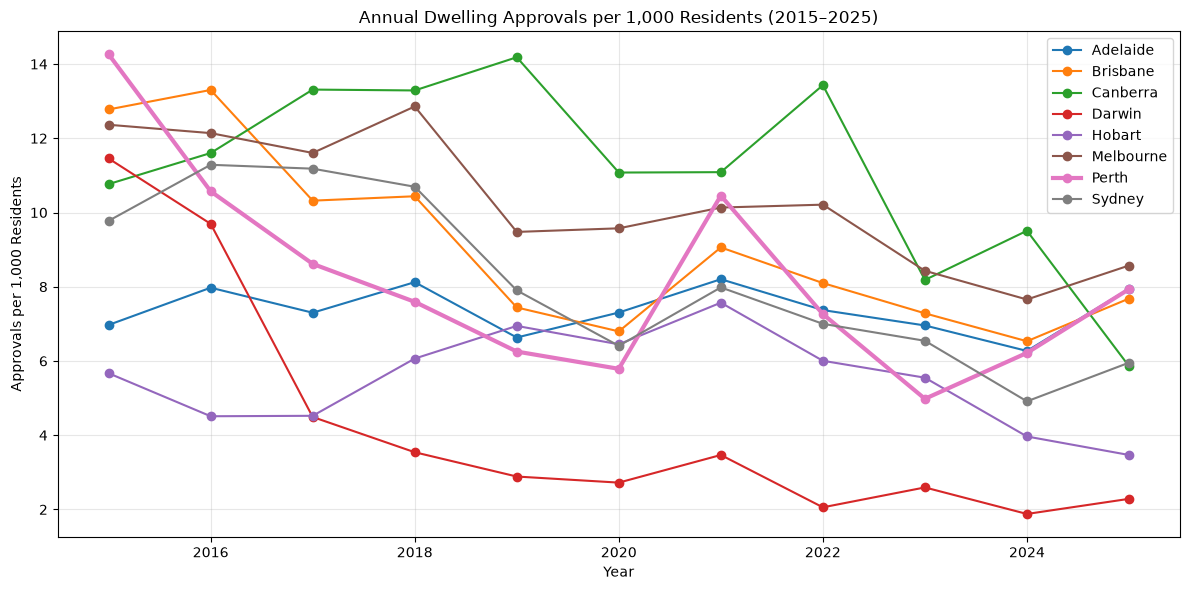

In [50]:
plt.figure(figsize=(12, 6))

for city, group in supply.groupby("city"):
    plt.plot(
        group["year"],
        group["approvals_per_1000"],
        marker="o",
        label=city,
        linewidth=3 if city == "Perth" else 1.5
    )

plt.title("Annual Dwelling Approvals per 1,000 Residents (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Approvals per 1,000 Residents")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Dwelling approvals per 1,000 residents show substantial differences across Australian capital cities.

Key findings:

Perth's approval rate declined considerably between 2015 and 2020, before temporarily recovering in 2021.

Approval activity declined again in 2022–2023, coinciding with the period leading into Perth's rapid house-price growth.

Approvals subsequently recovered through 2025, although they remained below their 2015 level.

Other capital cities exhibited different approval trends, indicating regional differences in housing construction activity.

Economic interpretation: Perth's relatively low dwelling approval rates during its recent housing boom are consistent with potential housing supply constraints. Strong population growth combined with limited additions to housing supply could contribute to upward pressure on property prices.

However, building approvals measure intended construction rather than completed dwellings. Further analysis is required before concluding that insufficient housing supply caused price increases.

In [51]:
# Combine annual property prices with housing supply data.
housing_supply = annual_prices.merge(
    supply[["city", "year", "approvals_per_1000"]],
    on=["city", "year"],
    how="inner"
)

# Inspect Perth's housing supply and price growth.
display(
    housing_supply[housing_supply["city"] == "Perth"][
        ["year", "price_growth_pct", "approvals_per_1000"]
    ]
)

,year,price_growth_pct,approvals_per_1000
66,2015,NaN,14.262080
67,2016,-3.165736,10.570688
68,2017,-2.692308,8.615563
69,2018,0.790514,7.593139
70,2019,-5.882353,6.253477
71,2020,-1.041667,5.788409
72,2021,13.684211,10.455152
73,2022,4.629630,7.262558
74,2023,6.194690,4.980002
75,2024,25.833333,6.217540


In [52]:
# Select Perth and sort chronologically.
perth_supply = housing_supply[
    housing_supply["city"] == "Perth"
].sort_values("year").copy()

# Use the previous year's dwelling approval rate.
perth_supply["approvals_lag1"] = (
    perth_supply["approvals_per_1000"].shift(1)
)

# Compare contemporaneous and lagged correlations.
print(
    "Same-year correlation:",
    perth_supply["approvals_per_1000"]
    .corr(perth_supply["price_growth_pct"]).round(3)
)

print(
    "One-year lag correlation:",
    perth_supply["approvals_lag1"]
    .corr(perth_supply["price_growth_pct"]).round(3)
)

Same-year correlation: -0.065
One-year lag correlation: -0.622


In [54]:
# Combine housing prices, population, and dwelling approvals.
model_data = annual_prices.merge(
    supply[
        ["city", "year", "population_growth_pct", "approvals_per_1000"]
    ],
    on=["city", "year"],
    how="inner"
).sort_values(["city", "year"])

# Create previous-year economic indicators.
model_data["population_growth_lag1"] = (
    model_data.groupby("city")["population_growth_pct"].shift(1)
)

model_data["approvals_lag1"] = (
    model_data.groupby("city")["approvals_per_1000"].shift(1)
)

display(model_data.head(10))

,year,city,median_price_aud,price_growth_pct,population_growth_pct,approvals_per_1000,population_growth_lag1,approvals_lag1
0,2015,Adelaide,420000.0,NaN,NaN,6.971119,NaN,NaN
1,2016,Adelaide,440000.0,4.761905,0.809947,7.973977,NaN,6.971119
2,2017,Adelaide,450000.0,2.272727,1.073443,7.299723,0.809947,7.973977
3,2018,Adelaide,468000.0,4.000000,1.150142,8.123150,1.073443,7.299723
4,2019,Adelaide,478500.0,2.243590,1.385279,6.632110,1.150142,8.123150
5,2020,Adelaide,487500.0,1.880878,1.482133,7.304946,1.385279,6.632110
6,2021,Adelaide,550000.0,12.820513,0.654602,8.202603,1.482133,7.304946
7,2022,Adelaide,663000.0,20.545455,1.385719,7.370727,0.654602,8.202603
8,2023,Adelaide,702000.0,5.882353,2.065999,6.956824,1.385719,7.370727
9,2024,Adelaide,785000.0,11.823362,1.496282,6.270172,2.065999,6.956824


We combine annual house-price growth, population growth, and dwelling approvals across eight Australian capital cities.

We also create one-year lagged economic indicators to investigate whether previous housing demand and supply conditions help predict subsequent house-price growth.

The relationships identified during EDA are preliminary and do not establish causality.

We incorporate the Reserve Bank of Australia's cash-rate data as an indicator of borrowing costs.

Higher interest rates generally increase mortgage financing costs and may reduce housing demand.

In [55]:
# Load the RBA monthly interest rate dataset.
rates_file = root / "data/raw/RBA cash-rate.csv"

# Skip the introductory metadata rows.
rates_raw = pd.read_csv(rates_file, skiprows=10)

print("Dataset shape:", rates_raw.shape)
print("Columns:", rates_raw.columns.tolist())

display(rates_raw.head())

Dataset shape: (689, 16)
Columns: ['Series ID', 'FIRMMCRT', 'FIRMMCRI', 'FIRMMCRIHM', 'FIRMMCRILM', 'FIRMMCRIVM', 'FIRMMCRINM', 'FIRMMBAB30', 'FIRMMBAB90', 'FIRMMBAB180', 'FIRMMOIS1', 'FIRMMOIS3', 'FIRMMOIS6', 'FIRMMTN1', 'FIRMMTN3', 'FIRMMTN6']


,Series ID,FIRMMCRT,FIRMMCRI,FIRMMCRIHM,FIRMMCRILM,FIRMMCRIVM,FIRMMCRINM,FIRMMBAB30,FIRMMBAB90,FIRMMBAB180,FIRMMOIS1,FIRMMOIS3,FIRMMOIS6,FIRMMTN1,FIRMMTN3,FIRMMTN6
0,30/06/1969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31/07/1969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,31/08/1969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,30/09/1969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,31/10/1969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
# Select the cash rate target series.
rates = rates_raw[["Series ID", "FIRMMCRT"]].copy()
rates.columns = ["date", "cash_rate_pct"]

# Convert dates and interest rates.
rates["date"] = pd.to_datetime(rates["date"], dayfirst=True)
rates["cash_rate_pct"] = pd.to_numeric(rates["cash_rate_pct"], errors="coerce")

# Assign observations to the financial year ending 30 June.
rates["year"] = rates["date"].dt.year + (rates["date"].dt.month > 6)

# Calculate the average cash rate for each financial year.
annual_rates = (
    rates[rates["year"].between(2015, 2025)]
    .groupby("year", as_index=False)
    .agg(
        cash_rate_pct=("cash_rate_pct", "mean"),
        months=("cash_rate_pct", "count")
    )
)

display(annual_rates)

,year,cash_rate_pct,months
0,2015,2.360000,12
1,2016,1.960000,12
2,2017,1.522500,12
3,2018,1.500000,12
4,2019,1.481667,12
5,2020,0.663333,12
6,2021,0.150833,12
7,2022,0.171667,12
8,2023,2.935000,12
9,2024,4.261667,12


In [57]:
# Merge annual interest rates with our existing economic indicators.
model_data = model_data.merge(
    annual_rates[["year", "cash_rate_pct"]],
    on="year",
    how="left"
)

# Use the previous year's interest rate for prediction.
model_data = model_data.sort_values(["city", "year"])

model_data["cash_rate_lag1"] = (
    model_data.groupby("city")["cash_rate_pct"].shift(1)
)

display(model_data.head(10))

,year,city,median_price_aud,price_growth_pct,population_growth_pct,approvals_per_1000,population_growth_lag1,approvals_lag1,cash_rate_pct,cash_rate_lag1
0,2015,Adelaide,420000.0,NaN,NaN,6.971119,NaN,NaN,2.360000,NaN
1,2016,Adelaide,440000.0,4.761905,0.809947,7.973977,NaN,6.971119,1.960000,2.360000
2,2017,Adelaide,450000.0,2.272727,1.073443,7.299723,0.809947,7.973977,1.522500,1.960000
3,2018,Adelaide,468000.0,4.000000,1.150142,8.123150,1.073443,7.299723,1.500000,1.522500
4,2019,Adelaide,478500.0,2.243590,1.385279,6.632110,1.150142,8.123150,1.481667,1.500000
5,2020,Adelaide,487500.0,1.880878,1.482133,7.304946,1.385279,6.632110,0.663333,1.481667
6,2021,Adelaide,550000.0,12.820513,0.654602,8.202603,1.482133,7.304946,0.150833,0.663333
7,2022,Adelaide,663000.0,20.545455,1.385719,7.370727,0.654602,8.202603,0.171667,0.150833
8,2023,Adelaide,702000.0,5.882353,2.065999,6.956824,1.385719,7.370727,2.935000,0.171667
9,2024,Adelaide,785000.0,11.823362,1.496282,6.270172,2.065999,6.956824,4.261667,2.935000


We extract the RBA cash rate target and calculate its average over each July–June financial year.

The cash rate represents monetary policy conditions and influences borrowing costs in the Australian housing market.

We create a one-year lagged cash-rate feature to support predicting subsequent house-price growth without using future economic observations.

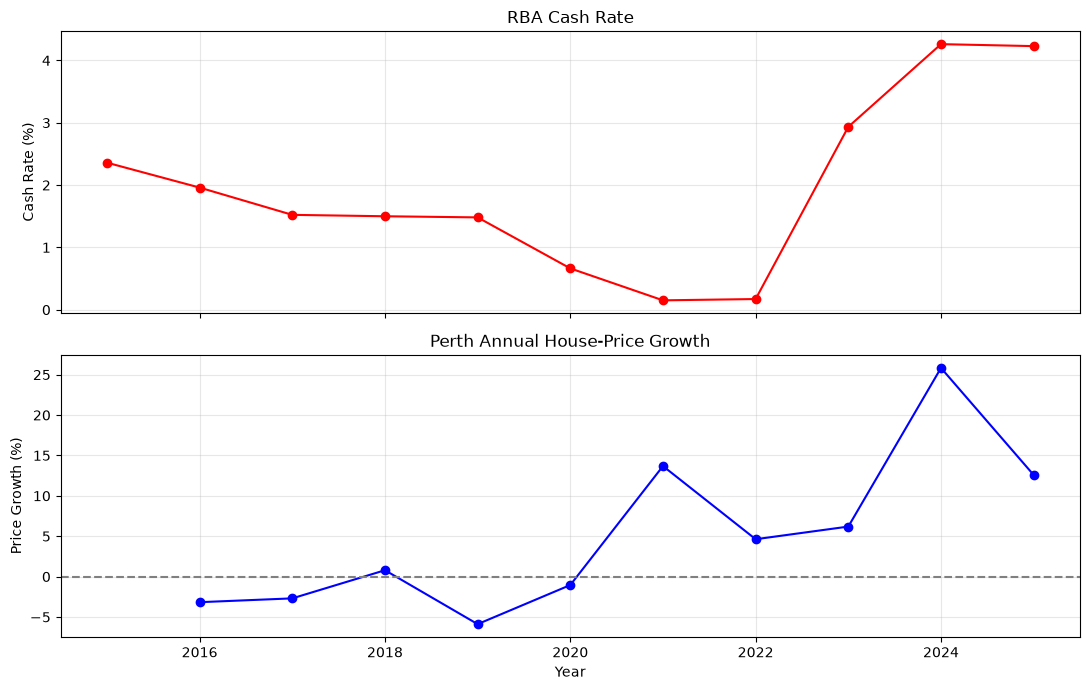

In [58]:
# Select Perth's annual housing data.
perth = model_data[model_data["city"] == "Perth"].sort_values("year")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Plot the RBA cash rate.
ax[0].plot(perth["year"], perth["cash_rate_pct"], color="red", marker="o")
ax[0].set_title("RBA Cash Rate")
ax[0].set_ylabel("Cash Rate (%)")
ax[0].grid(alpha=0.3)

# Plot Perth's annual house-price growth.
ax[1].plot(perth["year"], perth["price_growth_pct"], color="blue", marker="o")
ax[1].axhline(0, color="gray", linestyle="--")
ax[1].set_title("Perth Annual House-Price Growth")
ax[1].set_ylabel("Price Growth (%)")
ax[1].set_xlabel("Year")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Perth experienced substantial house-price growth during 2023–2025 despite higher RBA interest rates.

This suggests that borrowing costs alone may not adequately explain movements in Perth's housing market.

Population growth and dwelling approval activity are additional economic indicators worth considering when modelling house-price growth.

These findings motivate the use of multiple economic predictors rather than relying on interest rates alone. The relationships remain observational and do not establish causality.

In [59]:
# Select the target and three lagged economic predictors.
features = [
    "population_growth_lag1",
    "approvals_lag1",
    "cash_rate_lag1"
]

target = "price_growth_pct"

# Remove observations with missing modelling values.
ml_data = model_data.dropna(
    subset=features + [target]
).copy()

print("Dataset shape:", ml_data.shape)
print("Years:", ml_data["year"].min(), "-", ml_data["year"].max())
print("Cities:", ml_data["city"].nunique())

display(ml_data[["city", "year"] + features + [target]].head())

Dataset shape: (72, 10)
Years: 2017 - 2025
Cities: 8


,city,year,population_growth_lag1,approvals_lag1,cash_rate_lag1,price_growth_pct
2,Adelaide,2017,0.809947,7.973977,1.960000,2.272727
3,Adelaide,2018,1.073443,7.299723,1.522500,4.000000
4,Adelaide,2019,1.150142,8.123150,1.500000,2.243590
5,Adelaide,2020,1.385279,6.632110,1.481667,1.880878
6,Adelaide,2021,1.482133,7.304946,0.663333,12.820513


In [60]:
# Save the final dataset for machine learning.
output_file = root / "data/processed/ml_data.csv"

ml_data.to_csv(output_file, index=False)

print(f"Dataset saved to: {output_file}")
print(f"Dataset shape: {ml_data.shape}")

Dataset saved to: c:\Users\wongj\data_science_projects\australian-property-ml\data\processed\ml_data.csv
Dataset shape: (72, 10)


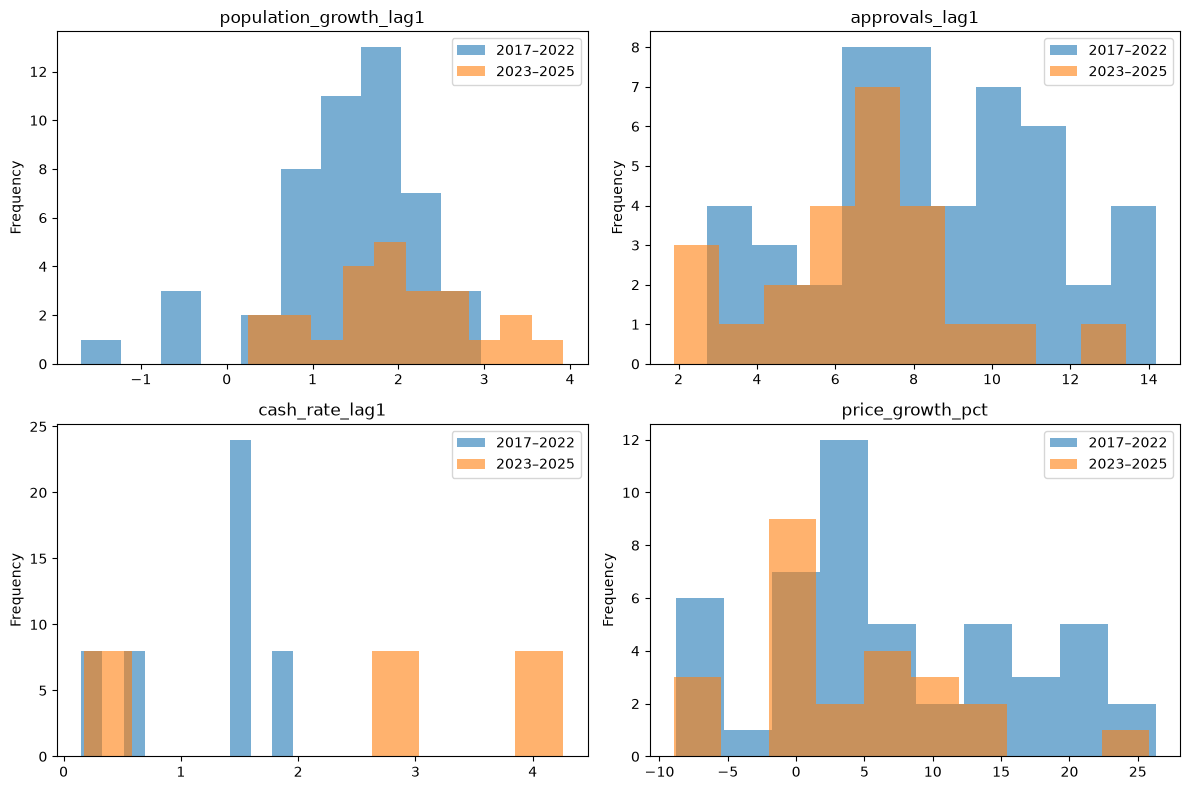

In [64]:
# Compare feature distributions between training and testing periods.
eda_train = ml_data[ml_data["year"] <= 2022]
eda_test = ml_data[ml_data["year"] >= 2023]

columns = [
    "population_growth_lag1",
    "approvals_lag1",
    "cash_rate_lag1",
    "price_growth_pct"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, columns):
    ax.hist(eda_train[col], bins=10, alpha=0.6, label="2017–2022")
    ax.hist(eda_test[col], bins=10, alpha=0.6, label="2023–2025")

    ax.set_title(col)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

We examined the distributions of population growth, dwelling approvals, interest rates, and house-price growth across the training (2017–2022) and testing (2023–2025) periods.

The most notable difference was the RBA cash rate. Training observations ranged from 0.15% to 1.96%, while testing observations reached 4.26%.

This distribution shift may explain some of the poor generalisation observed in Linear and Ridge Regression, particularly when combined with the small dataset and limited number of independent historical years.

We retain the original features without additional transformations. Feature scaling will be applied within modelling pipelines where appropriate.